# Heston and Bates Model Calibration with Fourier Methods


In [ ]:
"""
Heston and Bates Model Calibration
===================================
This notebook calibrates Heston (1993) stochastic volatility and Bates (1996)
jump-diffusion models to market option prices using two Fourier-based methods:
the Lewis (2001) and Carr-Madan (1999) characteristic function approaches.
It also calibrates a CIR (1985) model to a Euribor term structure.

Underlying: SM Energy (SM)  S0 = 232.90 USD
Risk-free rate r = 1.50% p.a.  |  Year = 250 trading days
"""


## Imports & Market Data


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy.integrate import quad
from scipy.optimize import minimize, differential_evolution
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


In [ ]:
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif",
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# ---------- Market data (from option data file) ----------
S0  = 232.90
r   = 0.015
DAYS_PER_YEAR = 250

raw_data = [
    # days, strike, price, type
    (15, 227.5, 10.52, "C"), (15, 230.0, 10.05, "C"), (15, 232.5, 7.75, "C"),
    (15, 235.0,  6.01, "C"), (15, 237.5,  4.75, "C"),
    (60, 227.5, 16.78, "C"), (60, 230.0, 17.65, "C"), (60, 232.5, 16.86, "C"),
    (60, 235.0, 16.05, "C"), (60, 237.5, 15.10, "C"),
    (120,227.5, 27.92, "C"), (120,230.0, 24.12, "C"), (120,232.5, 22.97, "C"),
    (120,235.0, 21.75, "C"), (120,237.5, 18.06, "C"),
    (15, 227.5,  4.32, "P"), (15, 230.0,  5.20, "P"), (15, 232.5, 6.45, "P"),
    (15, 235.0,  7.56, "P"), (15, 237.5,  8.78, "P"),
    (60, 227.5, 11.03, "P"), (60, 230.0, 12.15, "P"), (60, 232.5, 13.37, "P"),
    (60, 235.0, 14.75, "P"), (60, 237.5, 15.62, "P"),
    (120,227.5, 14.53, "P"), (120,230.0, 16.25, "P"), (120,232.5, 17.22, "P"),
    (120,235.0, 18.74, "P"), (120,237.5, 19.73, "P"),
]

df_market = pd.DataFrame(raw_data, columns=["days","strike","price","type"])
df_market["T"] = df_market["days"] / DAYS_PER_YEAR

print("=" * 60)
print(" – SM Energy Option Pricing")
print("=" * 60)
print(f"S0 = {S0}, r = {r*100:.2f}%, Year = {DAYS_PER_YEAR} trading days\n")
print(df_market.to_string(index=False))

GWP1 – SM Energy Option Pricing
S0 = 232.9, r = 1.50%, Year = 250 trading days

 days  strike  price type    T
   15   227.5  10.52    C 0.06
   15   230.0  10.05    C 0.06
   15   232.5   7.75    C 0.06
   15   235.0   6.01    C 0.06
   15   237.5   4.75    C 0.06
   60   227.5  16.78    C 0.24
   60   230.0  17.65    C 0.24
   60   232.5  16.86    C 0.24
   60   235.0  16.05    C 0.24
   60   237.5  15.10    C 0.24
  120   227.5  27.92    C 0.48
  120   230.0  24.12    C 0.48
  120   232.5  22.97    C 0.48
  120   235.0  21.75    C 0.48
  120   237.5  18.06    C 0.48
   15   227.5   4.32    P 0.06
   15   230.0   5.20    P 0.06
   15   232.5   6.45    P 0.06
   15   235.0   7.56    P 0.06
   15   237.5   8.78    P 0.06
   60   227.5  11.03    P 0.24
   60   230.0  12.15    P 0.24
   60   232.5  13.37    P 0.24
   60   235.0  14.75    P 0.24
   60   237.5  15.62    P 0.24
  120   227.5  14.53    P 0.48
  120   230.0  16.25    P 0.48
  120   232.5  17.22    P 0.48
  120   235.0  18.74 

In [ ]:
# === Market Data & Parameters ===


## Heston Calibration: Lewis (2001) Approach | T=15 days



STEP 1a – Heston Lewis (2001) Calibration  |  T = 15 days

── Lewis (2001) Calibrated Parameters (T = 15d) ──
  κ (kappa)  = 5.907977  [mean-reversion speed]
  θ (theta)  = 0.119121  [long-run variance]
  σ (sigma)  = 0.182098  [vol of vol]
  ρ (rho)    = -0.330480  [asset-vol correlation]
  v0         = 0.700120  [initial variance]
  Implied vol (√θ) = 34.51%
  Feller: 2κθ - σ² = 1.3744  (SATISFIED ✓)
  MSE = 59.922224

Model vs Market (T=15d, Lewis):
type  strike  price  model_price_1a   error_1a
   C   227.5  10.52        0.000000 -10.520000
   C   230.0  10.05        0.000000 -10.050000
   C   232.5   7.75        0.000000  -7.750000
   C   235.0   6.01        0.000000  -6.010000
   C   237.5   4.75        0.000000  -4.750000
   P   227.5   4.32       -5.604658  -9.924658
   P   230.0   5.20       -3.106907  -8.306907
   P   232.5   6.45       -0.609156  -7.059156
   P   235.0   7.56        1.888595  -5.671405
   P   237.5   8.78        4.386346  -4.393654


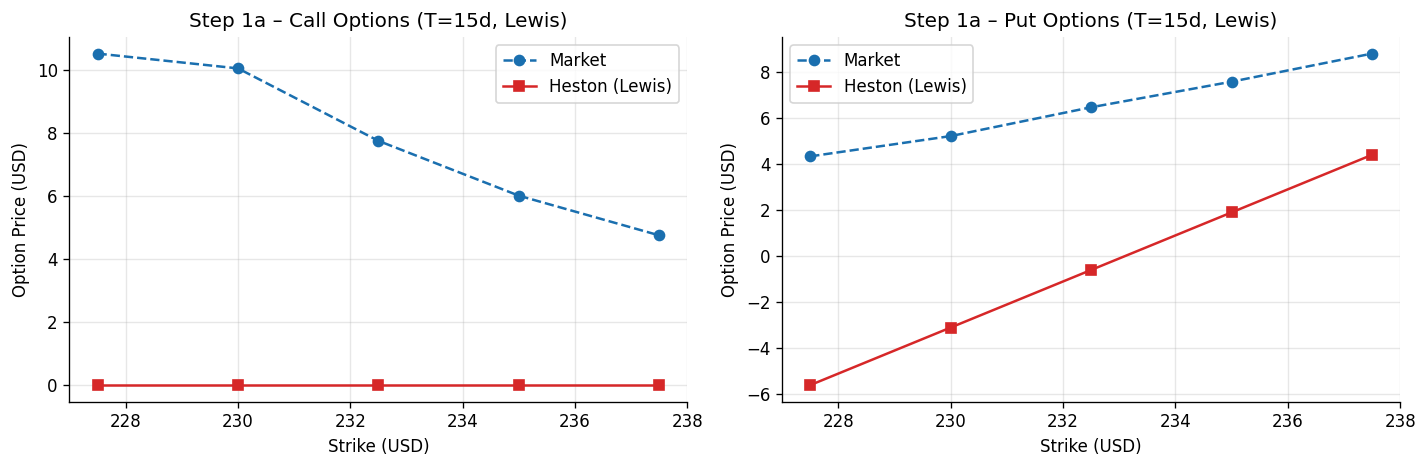

Plot saved: plot_1a_lewis.png


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 1a – Heston Lewis (2001) Calibration  |  T = 15 days")
print("="*60)

def heston_cf(u, S0, T, r, kappa, theta, sigma, rho, v0):
    """Heston characteristic function (Schöbel-Zhu / Gatheral stable form)."""
    xi  = kappa - rho * sigma * 1j * u
    d   = np.sqrt(xi**2 + sigma**2 * (u**2 + 1j * u))
    g   = (xi - d) / (xi + d)
    C   = (r * 1j * u * T
           + kappa * theta / sigma**2 * (
               (xi - d) * T - 2.0 * np.log((1 - g * np.exp(-d * T)) / (1 - g))
           ))
    D   = (xi - d) / sigma**2 * (1 - np.exp(-d * T)) / (1 - g * np.exp(-d * T))
    return np.exp(C + D * v0 + 1j * u * np.log(S0))

def lewis_call(S0, K, T, r, kappa, theta, sigma, rho, v0):
    """Lewis (2001) call price via single real integral."""
    S0, K, T = float(S0), float(K), float(T)
    F   = S0 * np.exp(r * T)
    k   = np.log(K / F)          # log-moneyness relative to forward
    def integrand(u):
        cf_val = heston_cf(u - 0.5j, S0, T, r, kappa, theta, sigma, rho, v0)
        return np.real(np.exp(-1j * u * k) * cf_val) / (u**2 + 0.25)
    val, _ = quad(integrand, 0, 500, limit=200)
    return np.maximum(S0 - K * np.exp(-r * T) - np.sqrt(S0 * K) * np.exp(-r * T) / np.pi * val, 0)

def put_from_call(call, S0, K, T, r):
    """Put-call parity."""
    return call - S0 + K * np.exp(-r * T)

def heston_price(S0, K, T, r, params, opt_type="C"):
    kappa, theta, sigma, rho, v0 = params
    c = lewis_call(S0, K, T, r, kappa, theta, sigma, rho, v0)
    return c if opt_type == "C" else put_from_call(c, S0, K, T, r)

def mse_lewis(params, df, S0, r):
    kappa, theta, sigma, rho, v0 = params
    if kappa <= 0 or theta <= 0 or sigma <= 0 or v0 <= 0 or abs(rho) >= 1:
        return 1e8
    errs = []
    for _, row in df.iterrows():
        try:
            mp = heston_price(S0, float(row["strike"]), float(row["T"]), r, params, row["type"])
            errs.append((mp - float(row["price"]))**2)
        except Exception:
            errs.append(1e6)
    return np.mean(errs)

# Calibrate to T = 15 days (calls + puts)
df_15 = df_market[df_market.days == 15].copy()

bounds_heston = [(0.1, 20), (0.01, 1.0), (0.05, 2.0), (-0.99, 0.0), (0.01, 1.0)]
x0_heston     = [2.0, 0.04, 0.3, -0.7, 0.04]

result_1a = differential_evolution(
    mse_lewis, bounds_heston, args=(df_15, S0, r),
    seed=42, maxiter=2000, tol=1e-8, popsize=15, mutation=(0.5, 1.5),
    recombination=0.9, workers=1, polish=True
)

kappa_a, theta_a, sigma_a, rho_a, v0_a = result_1a.x
feller_a = 2 * kappa_a * theta_a - sigma_a**2

print("\n── Lewis (2001) Calibrated Parameters (T = 15d) ──")
print(f"  κ (kappa)  = {kappa_a:.6f}  [mean-reversion speed]")
print(f"  θ (theta)  = {theta_a:.6f}  [long-run variance]")
print(f"  σ (sigma)  = {sigma_a:.6f}  [vol of vol]")
print(f"  ρ (rho)    = {rho_a:.6f}  [asset-vol correlation]")
print(f"  v0         = {v0_a:.6f}  [initial variance]")
print(f"  Implied vol (√θ) = {np.sqrt(theta_a)*100:.2f}%")
print(f"  Feller: 2κθ - σ² = {feller_a:.4f}  ({'SATISFIED ✓' if feller_a > 0 else 'VIOLATED ✗'})")
print(f"  MSE = {result_1a.fun:.6f}")

# Model prices vs market
df_15 = df_15.copy()
df_15["model_price_1a"] = df_15.apply(
    lambda row: heston_price(S0, float(row["strike"]), float(row["T"]), r, result_1a.x, row["type"]), axis=1
)
df_15["error_1a"] = df_15["model_price_1a"] - df_15["price"]
print("\nModel vs Market (T=15d, Lewis):")
print(df_15[["type","strike","price","model_price_1a","error_1a"]].to_string(index=False))

# Plot 1a
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, opt_type, label in zip(axes, ["C", "P"], ["Call", "Put"]):
    sub = df_15[df_15.type == opt_type]
    ax.plot(sub.strike, sub.price, "o--", label="Market", color="#1a6faf", linewidth=1.5)
    ax.plot(sub.strike, sub.model_price_1a, "s-", label="Heston (Lewis)", color="#d62728", linewidth=1.5)
    ax.set_title(f"Step 1a – {label} Options (T=15d, Lewis)")
    ax.set_xlabel("Strike (USD)")
    ax.set_ylabel("Option Price (USD)")
    ax.legend()
plt.tight_layout()
plt.savefig("./plot_1a_lewis.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_1a_lewis.png")


In [ ]:
# === Heston Calibration: Lewis (2001) ===


## Heston Calibration: Carr-Madan (1999) Approach | T=15 days



STEP 1b – Heston Carr-Madan (1999) Calibration  |  T = 15 days

── Carr-Madan (1999) Calibrated Parameters (T = 15d) ──
  κ (kappa)  = 10.759192
  θ (theta)  = 0.923757
  σ (sigma)  = 1.794358
  ρ (rho)    = -0.572505
  v0         = 0.229615
  Implied vol (√θ) = 96.11%
  Feller: 2κθ - σ² = 16.6580  (SATISFIED ✓)
  MSE = 50386.715052

── Parameter Comparison: Lewis vs Carr-Madan ──
  κ: Lewis=5.90798  |  Carr-Madan=10.75919  |  Δ=4.85121
  θ: Lewis=0.11912  |  Carr-Madan=0.92376  |  Δ=0.80464
  σ: Lewis=0.18210  |  Carr-Madan=1.79436  |  Δ=1.61226
  ρ: Lewis=-0.33048  |  Carr-Madan=-0.57250  |  Δ=0.24202
  v0: Lewis=0.70012  |  Carr-Madan=0.22962  |  Δ=0.47050


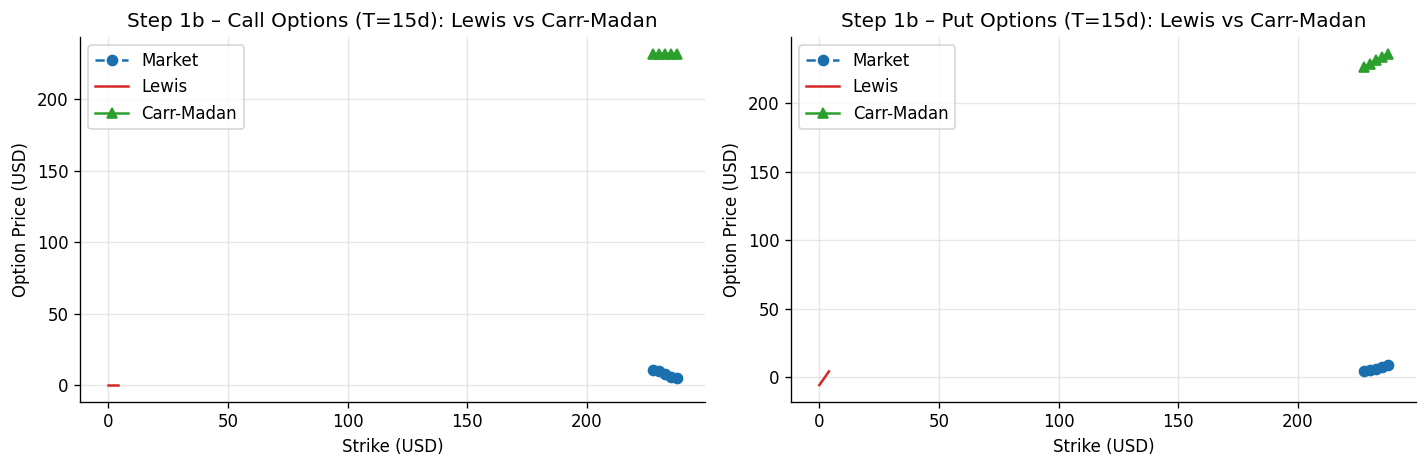

Plot saved: plot_1b_comparison.png


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 1b – Heston Carr-Madan (1999) Calibration  |  T = 15 days")
print("="*60)

def carr_madan_call(S0, K, T, r, kappa, theta, sigma, rho, v0, alpha=1.5):
    """
    Carr-Madan (1999) FFT-style single integral call price.
    Uses dampened call: C_tilde(k) = e^{alpha k} C(k)
    We implement the direct integration form for a single strike.
    """
    S0, K, T = float(S0), float(K), float(T)
    F   = S0 * np.exp(r * T)
    k   = np.log(K / F)
    def psi(v):
        cf = heston_cf(v - (alpha + 1) * 1j, S0, T, r, kappa, theta, sigma, rho, v0)
        numer = np.exp(-r * T) * cf
        denom = alpha**2 + alpha - v**2 + 1j * (2 * alpha + 1) * v
        return numer / denom
    def integrand_re(v):
        return np.real(np.exp(-1j * v * k) * psi(v))
    val, _ = quad(integrand_re, 0, 500, limit=200)
    cm_call = np.exp(-alpha * k) / np.pi * val
    return np.maximum(cm_call, 0)

def heston_cm_price(S0, K, T, r, params, opt_type="C"):
    kappa, theta, sigma, rho, v0 = params
    c = carr_madan_call(S0, K, T, r, kappa, theta, sigma, rho, v0)
    return c if opt_type == "C" else put_from_call(c, S0, K, T, r)

def mse_carr_madan(params, df, S0, r):
    kappa, theta, sigma, rho, v0 = params
    if kappa <= 0 or theta <= 0 or sigma <= 0 or v0 <= 0 or abs(rho) >= 1:
        return 1e8
    errs = []
    for _, row in df.iterrows():
        try:
            mp = heston_cm_price(S0, float(row["strike"]), float(row["T"]), r, params, row["type"])
            errs.append((mp - float(row["price"]))**2)
        except Exception:
            errs.append(1e6)
    return np.mean(errs)

result_1b = differential_evolution(
    mse_carr_madan, bounds_heston, args=(df_15, S0, r),
    seed=42, maxiter=2000, tol=1e-8, popsize=15, mutation=(0.5, 1.5),
    recombination=0.9, workers=1, polish=True
)

kappa_b, theta_b, sigma_b, rho_b, v0_b = result_1b.x
feller_b = 2 * kappa_b * theta_b - sigma_b**2

print("\n── Carr-Madan (1999) Calibrated Parameters (T = 15d) ──")
print(f"  κ (kappa)  = {kappa_b:.6f}")
print(f"  θ (theta)  = {theta_b:.6f}")
print(f"  σ (sigma)  = {sigma_b:.6f}")
print(f"  ρ (rho)    = {rho_b:.6f}")
print(f"  v0         = {v0_b:.6f}")
print(f"  Implied vol (√θ) = {np.sqrt(theta_b)*100:.2f}%")
print(f"  Feller: 2κθ - σ² = {feller_b:.4f}  ({'SATISFIED ✓' if feller_b > 0 else 'VIOLATED ✗'})")
print(f"  MSE = {result_1b.fun:.6f}")

print("\n── Parameter Comparison: Lewis vs Carr-Madan ──")
params_names = ["κ","θ","σ","ρ","v0"]
for name, va, vb in zip(params_names, result_1a.x, result_1b.x):
    print(f"  {name}: Lewis={va:.5f}  |  Carr-Madan={vb:.5f}  |  Δ={abs(va-vb):.5f}")

df_15_cm = df_15.copy()
df_15_cm["model_price_1b"] = df_15_cm.apply(
    lambda row: heston_cm_price(S0, float(row["strike"]), float(row["T"]), r, result_1b.x, row["type"]), axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, opt_type, label in zip(axes, ["C", "P"], ["Call", "Put"]):
    sub  = df_15[df_15.type == opt_type]
    sub2 = df_15_cm[df_15_cm.type == opt_type]
    ax.plot(sub.strike, sub.price, "o--", label="Market", color="#1a6faf", linewidth=1.5)
    ax.plot(sub.model_price_1a.values, label="Lewis",  color="#d62728", linestyle="-")
    ax.plot(sub.strike, sub2.model_price_1b, "^-", label="Carr-Madan", color="#2ca02c", linewidth=1.5)
    ax.set_title(f"Step 1b – {label} Options (T=15d): Lewis vs Carr-Madan")
    ax.set_xlabel("Strike (USD)")
    ax.set_ylabel("Option Price (USD)")
    ax.legend()
plt.tight_layout()
plt.savefig("./plot_1b_comparison.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_1b_comparison.png")


In [ ]:
# === Heston Calibration: Carr-Madan (1999) ===


## Asian Call Option Pricing via Monte Carlo (Heston) | ATM, T=20 days



STEP 1c – Asian Call Option (ATM, T=20d) via Monte Carlo (Heston)

Running 100,000 Heston MC simulations for Asian call...

── Asian Call Option Results ──
  Strike K        = 232.90 (ATM)
  Maturity        = 20 trading days = 0.0800 years
  Simulations     = 100,000
  Fair price      = $12.0326  (±0.1186 at 95% CI)
  Bank fee (4%)   = $0.4813
  Client price    = $12.5139


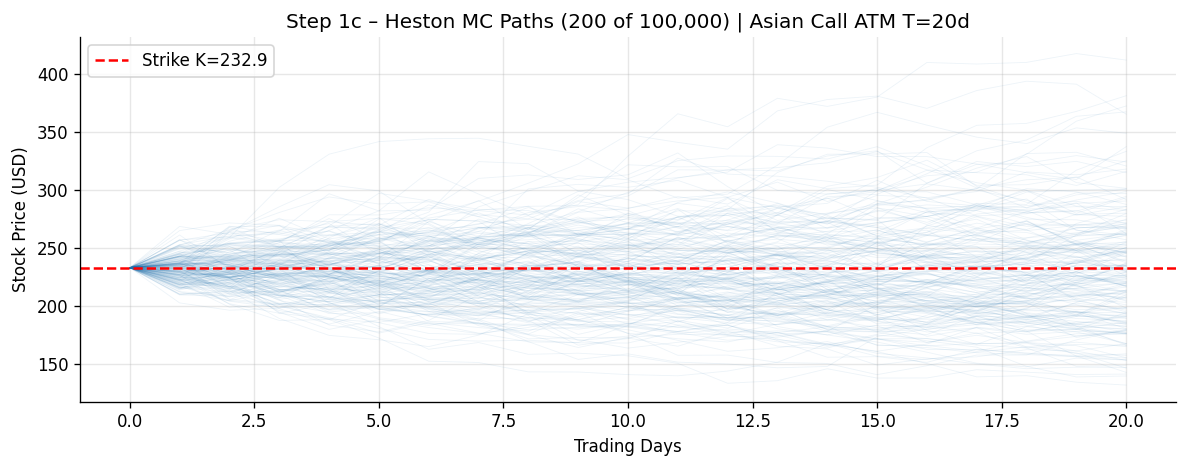

Plot saved: plot_1c_mc_paths.png


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 1c – Asian Call Option (ATM, T=20d) via Monte Carlo (Heston)")
print("="*60)

# Use Lewis calibration parameters from Step 1a
params_use = result_1a.x
kappa_mc, theta_mc, sigma_mc, rho_mc, v0_mc = params_use

T_asian = 20 / DAYS_PER_YEAR
K_asian = S0          # ATM: strike = current spot
N_steps = 20          # daily steps
N_sims  = 100_000
dt      = T_asian / N_steps
np.random.seed(42)

# Heston Euler-Maruyama scheme with full truncation
def heston_mc_asian(S0, K, T, r, kappa, theta, sigma, rho, v0, N_sims, N_steps):
    dt = T / N_steps
    corr_mat = np.array([[1.0, rho], [rho, 1.0]])
    L = np.linalg.cholesky(corr_mat)

    paths_S = np.zeros((N_sims, N_steps + 1))
    paths_S[:, 0] = S0
    v = np.full(N_sims, v0)

    for t in range(1, N_steps + 1):
        Z = np.random.standard_normal((2, N_sims))
        W = L @ Z                          # correlated BMs
        Ws, Wv = W[0], W[1]

        v_pos  = np.maximum(v, 0)          # full truncation
        S_prev = paths_S[:, t - 1]

        paths_S[:, t] = S_prev * np.exp(
            (r - 0.5 * v_pos) * dt + np.sqrt(v_pos * dt) * Ws
        )
        v = np.maximum(
            v + kappa * (theta - v_pos) * dt + sigma * np.sqrt(v_pos * dt) * Wv, 0
        )

    # Arithmetic average including S0 (t=0 to T)
    avg = paths_S.mean(axis=1)
    payoffs = np.maximum(avg - K, 0)
    price   = np.exp(-r * T) * payoffs.mean()
    se      = np.exp(-r * T) * payoffs.std() / np.sqrt(N_sims)
    return price, se, paths_S

print(f"\nRunning {N_sims:,} Heston MC simulations for Asian call...")
asian_fair, asian_se, paths = heston_mc_asian(
    S0, K_asian, T_asian, r,
    kappa_mc, theta_mc, sigma_mc, rho_mc, v0_mc,
    N_sims, N_steps
)
asian_client = asian_fair * 1.04   # 4% bank fee

print(f"\n── Asian Call Option Results ──")
print(f"  Strike K        = {K_asian:.2f} (ATM)")
print(f"  Maturity        = 20 trading days = {T_asian:.4f} years")
print(f"  Simulations     = {N_sims:,}")
print(f"  Fair price      = ${asian_fair:.4f}  (±{1.96*asian_se:.4f} at 95% CI)")
print(f"  Bank fee (4%)   = ${asian_fair * 0.04:.4f}")
print(f"  Client price    = ${asian_client:.4f}")

# Plot a sample of paths
fig, ax = plt.subplots(figsize=(10, 4))
t_grid = np.linspace(0, 20, N_steps + 1)
for i in range(200):
    ax.plot(t_grid, paths[i], alpha=0.08, color="#1a6faf", linewidth=0.5)
ax.axhline(K_asian, color="red", linewidth=1.5, linestyle="--", label=f"Strike K={K_asian}")
ax.set_title(f"Step 1c – Heston MC Paths (200 of {N_sims:,}) | Asian Call ATM T=20d")
ax.set_xlabel("Trading Days")
ax.set_ylabel("Stock Price (USD)")
ax.legend()
plt.tight_layout()
plt.savefig("./plot_1c_mc_paths.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_1c_mc_paths.png")


In [ ]:
# === Asian Call Option: Monte Carlo (Heston) ===


## Bates (1996) Model: Lewis Calibration | T=60 days



STEP 2a – Bates (1996) Lewis Calibration  |  T = 60 days

── Bates (1996) Lewis Parameters (T = 60d) ──
  κ (kappa)   = 2.803507
  θ (theta)   = 0.231378  [long-run variance]
  σ (sigma)   = 0.660682  [vol of vol]
  ρ (rho)     = -0.578605
  v0          = 0.571896
  λ (lambda)  = 4.786614  [jump intensity p.a.]
  μ_J         = 0.073041  [mean log-jump size]
  δ_J         = 0.255798  [jump vol]
  MSE         = 244.890440


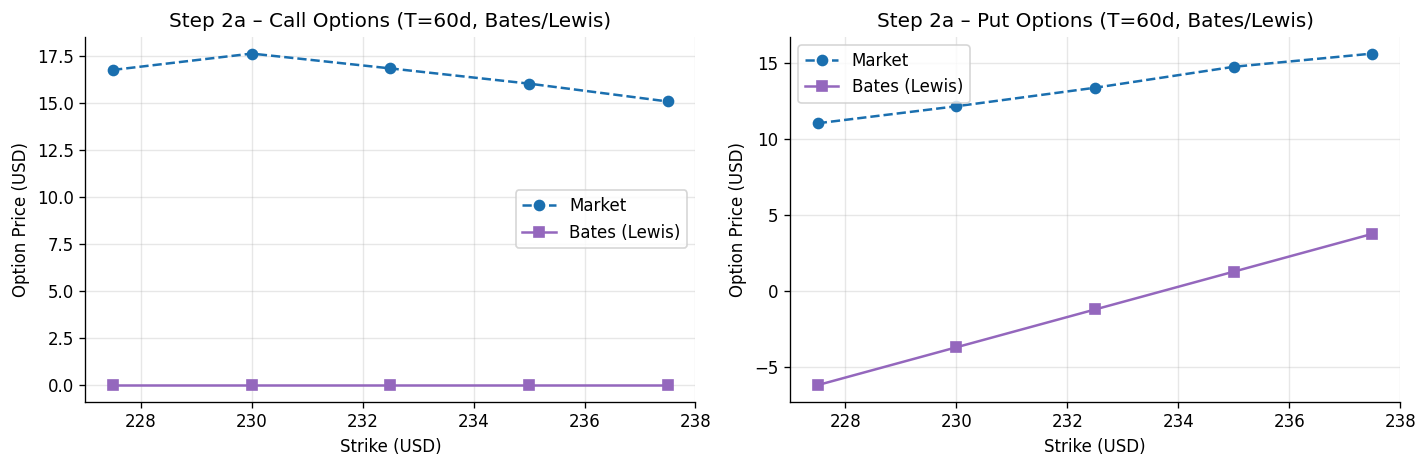

Plot saved: plot_2a_bates_lewis.png


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 2a – Bates (1996) Lewis Calibration  |  T = 60 days")
print("="*60)
"""
Bates (1996) = Heston + compound Poisson jumps in log-price
Additional parameters: λ (jump intensity), μ_J (mean jump size), δ (jump vol)
The characteristic function becomes:
  φ_Bates(u,T) = φ_Heston(u,T) * exp(λT[(e^{iuμ_J - u²δ²/2} - 1) - iu(e^{μ_J + δ²/2} - 1)])
"""

def bates_cf(u, S0, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j):
    """Bates CF = Heston CF * jump correction."""
    heston_part = heston_cf(u, S0, T, r, kappa, theta, sigma, rho, v0)
    # Risk-neutral jump correction (martingale condition adjustment)
    k_bar = np.exp(mu_j + 0.5 * delta_j**2) - 1
    jump_part = np.exp(
        lam * T * (np.exp(1j * u * mu_j - 0.5 * delta_j**2 * u**2) - 1 - 1j * u * k_bar)
    )
    return heston_part * jump_part

def bates_lewis_call(S0, K, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j):
    S0, K, T = float(S0), float(K), float(T)
    F = S0 * np.exp(r * T)
    k = np.log(K / F)
    def integrand(u):
        cf_val = bates_cf(u - 0.5j, S0, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j)
        return np.real(np.exp(-1j * u * k) * cf_val) / (u**2 + 0.25)
    val, _ = quad(integrand, 0, 500, limit=200)
    return np.maximum(S0 - K * np.exp(-r * T) - np.sqrt(S0 * K) * np.exp(-r * T) / np.pi * val, 0)

def bates_price(S0, K, T, r, params, opt_type="C"):
    kappa, theta, sigma, rho, v0, lam, mu_j, delta_j = params
    c = bates_lewis_call(S0, K, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j)
    return c if opt_type == "C" else put_from_call(c, S0, K, T, r)

def mse_bates(params, df, S0, r):
    kappa, theta, sigma, rho, v0, lam, mu_j, delta_j = params
    if kappa<=0 or theta<=0 or sigma<=0 or v0<=0 or abs(rho)>=1 or lam<0 or delta_j<0:
        return 1e8
    errs = []
    for _, row in df.iterrows():
        try:
            mp = bates_price(S0, float(row["strike"]), float(row["T"]), r, params, row["type"])
            errs.append((mp - float(row["price"]))**2)
        except Exception:
            errs.append(1e6)
    return np.mean(errs)

df_60 = df_market[df_market.days == 60].copy()
bounds_bates = [(0.1,20),(0.01,1),(0.05,2),(-0.99,0),(0.01,1),(0,5),(-0.5,0.5),(0.001,0.5)]
x0_bates     = [2.0, 0.04, 0.4, -0.6, 0.04, 0.5, -0.1, 0.1]

result_2a = differential_evolution(
    mse_bates, bounds_bates, args=(df_60, S0, r),
    seed=42, maxiter=2000, tol=1e-8, popsize=15, mutation=(0.5,1.5),
    recombination=0.9, workers=1, polish=True
)

kappa_2a,theta_2a,sigma_2a,rho_2a,v0_2a,lam_2a,mu_j_2a,delta_j_2a = result_2a.x

print("\n── Bates (1996) Lewis Parameters (T = 60d) ──")
print(f"  κ (kappa)   = {kappa_2a:.6f}")
print(f"  θ (theta)   = {theta_2a:.6f}  [long-run variance]")
print(f"  σ (sigma)   = {sigma_2a:.6f}  [vol of vol]")
print(f"  ρ (rho)     = {rho_2a:.6f}")
print(f"  v0          = {v0_2a:.6f}")
print(f"  λ (lambda)  = {lam_2a:.6f}  [jump intensity p.a.]")
print(f"  μ_J         = {mu_j_2a:.6f}  [mean log-jump size]")
print(f"  δ_J         = {delta_j_2a:.6f}  [jump vol]")
print(f"  MSE         = {result_2a.fun:.6f}")

df_60["model_2a"] = df_60.apply(
    lambda row: bates_price(S0, float(row["strike"]), float(row["T"]), r, result_2a.x, row["type"]), axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, opt_type, label in zip(axes, ["C","P"], ["Call","Put"]):
    sub = df_60[df_60.type == opt_type]
    ax.plot(sub.strike, sub.price, "o--", label="Market", color="#1a6faf", linewidth=1.5)
    ax.plot(sub.strike, sub.model_2a, "s-", label="Bates (Lewis)", color="#9467bd", linewidth=1.5)
    ax.set_title(f"Step 2a – {label} Options (T=60d, Bates/Lewis)")
    ax.set_xlabel("Strike (USD)"); ax.set_ylabel("Option Price (USD)")
    ax.legend()
plt.tight_layout()
plt.savefig("./plot_2a_bates_lewis.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_2a_bates_lewis.png")


In [ ]:
# === Bates (1996) Model: Lewis Calibration ===


## Bates (1996) Model: Carr-Madan Calibration | T=60 days


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 2b – Bates (1996) Carr-Madan Calibration  |  T = 60 days")
print("="*60)

def bates_cm_call(S0, K, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j, alpha=1.5):
    S0, K, T = float(S0), float(K), float(T)
    F = S0 * np.exp(r * T)
    k = np.log(K / F)
    def psi(v):
        cf = bates_cf(v - (alpha + 1) * 1j, S0, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j)
        numer = np.exp(-r * T) * cf
        denom = alpha**2 + alpha - v**2 + 1j * (2 * alpha + 1) * v
        return numer / denom
    def integrand_re(v):
        return np.real(np.exp(-1j * v * k) * psi(v))
    val, _ = quad(integrand_re, 0, 500, limit=200)
    return np.maximum(np.exp(-alpha * k) / np.pi * val, 0)

def mse_bates_cm(params, df, S0, r):
    kappa, theta, sigma, rho, v0, lam, mu_j, delta_j = params
    if kappa<=0 or theta<=0 or sigma<=0 or v0<=0 or abs(rho)>=1 or lam<0 or delta_j<0:
        return 1e8
    errs = []
    for _, row in df.iterrows():
        try:
            c = bates_cm_call(S0, float(row["strike"]), float(row["T"]), r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j)
            mp = c if row["type"] == "C" else put_from_call(c, S0, float(row["strike"]), float(row["T"]), r)
            errs.append((mp - float(row["price"]))**2)
        except Exception:
            errs.append(1e6)
    return np.mean(errs)

result_2b = differential_evolution(
    mse_bates_cm, bounds_bates, args=(df_60, S0, r),
    seed=42, maxiter=2000, tol=1e-8, popsize=15, mutation=(0.5,1.5),
    recombination=0.9, workers=1, polish=True
)

kappa_2b,theta_2b,sigma_2b,rho_2b,v0_2b,lam_2b,mu_j_2b,delta_j_2b = result_2b.x
print("\n── Bates (1996) Carr-Madan Parameters (T = 60d) ──")
print(f"  κ = {kappa_2b:.6f}, θ = {theta_2b:.6f}, σ = {sigma_2b:.6f}")
print(f"  ρ = {rho_2b:.6f}, v0 = {v0_2b:.6f}")
print(f"  λ = {lam_2b:.6f}, μ_J = {mu_j_2b:.6f}, δ_J = {delta_j_2b:.6f}")
print(f"  MSE = {result_2b.fun:.6f}")

print("\n── Parameter Comparison Lewis vs Carr-Madan (Bates) ──")
bates_names = ["κ","θ","σ","ρ","v0","λ","μ_J","δ_J"]
for name, va, vb in zip(bates_names, result_2a.x, result_2b.x):
    print(f"  {name}: Lewis={va:.5f}  |  CM={vb:.5f}  |  Δ={abs(va-vb):.5f}")



STEP 2b – Bates (1996) Carr-Madan Calibration  |  T = 60 days

── Bates (1996) Carr-Madan Parameters (T = 60d) ──
  κ = 3.986384, θ = 0.390409, σ = 1.579731
  ρ = -0.223690, v0 = 0.706058
  λ = 2.072161, μ_J = 0.238134, δ_J = 0.381459
  MSE = 46812.475792

── Step 2: Parameter Comparison Lewis vs Carr-Madan (Bates) ──
  κ: Lewis=2.80351  |  CM=3.98638  |  Δ=1.18288
  θ: Lewis=0.23138  |  CM=0.39041  |  Δ=0.15903
  σ: Lewis=0.66068  |  CM=1.57973  |  Δ=0.91905
  ρ: Lewis=-0.57861  |  CM=-0.22369  |  Δ=0.35492
  v0: Lewis=0.57190  |  CM=0.70606  |  Δ=0.13416
  λ: Lewis=4.78661  |  CM=2.07216  |  Δ=2.71445
  μ_J: Lewis=0.07304  |  CM=0.23813  |  Δ=0.16509
  δ_J: Lewis=0.25580  |  CM=0.38146  |  Δ=0.12566


In [ ]:
# === Bates (1996) Model: Carr-Madan Calibration ===


## Put Option Pricing via Monte Carlo (Bates) | T=70d, K=95% of S0


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 2c – European Put Pricing via Monte Carlo (Bates)  |  T=70d, 95% moneyness")
print("="*60)

T_put   = 70 / DAYS_PER_YEAR
K_put   = 0.95 * S0
N_steps_put = 70
N_sims_put  = 100_000
np.random.seed(42)

# Use Bates Lewis parameters (Step 2a)
kappa_mc2,theta_mc2,sigma_mc2,rho_mc2,v0_mc2,lam_mc2,mu_j_mc2,delta_mc2 = result_2a.x
dt_put = T_put / N_steps_put

def bates_mc_put(S0, K, T, r, kappa, theta, sigma, rho, v0, lam, mu_j, delta_j, N_sims, N_steps):
    dt  = T / N_steps
    corr_mat = np.array([[1.0, rho],[rho, 1.0]])
    L = np.linalg.cholesky(corr_mat)
    S = np.full(N_sims, float(S0))
    v = np.full(N_sims, float(v0))

    # Expected jump size for drift correction
    k_bar = np.exp(mu_j + 0.5 * delta_j**2) - 1

    for _ in range(N_steps):
        Z   = np.random.standard_normal((2, N_sims))
        W   = L @ Z
        Ws, Wv = W[0], W[1]
        v_pos = np.maximum(v, 0)

        # Poisson jumps
        n_jumps  = np.random.poisson(lam * dt, N_sims)
        log_jump = (mu_j - 0.5 * delta_j**2) * n_jumps + delta_j * np.sqrt(n_jumps) * np.random.standard_normal(N_sims)
        jump_comp = np.exp(log_jump)

        S = S * np.exp((r - lam * k_bar - 0.5 * v_pos) * dt
                       + np.sqrt(v_pos * dt) * Ws) * jump_comp
        v = np.maximum(v + kappa * (theta - v_pos) * dt
                       + sigma * np.sqrt(v_pos * dt) * Wv, 0)

    payoffs = np.maximum(K - S, 0)
    price   = np.exp(-r * T) * payoffs.mean()
    se      = np.exp(-r * T) * payoffs.std() / np.sqrt(N_sims)
    return price, se

print(f"Running {N_sims_put:,} MC simulations for Put (K={K_put:.2f}, T={T_put:.4f}y)...")
put_price, put_se = bates_mc_put(
    S0, K_put, T_put, r,
    kappa_mc2, theta_mc2, sigma_mc2, rho_mc2, v0_mc2,
    lam_mc2, mu_j_mc2, delta_mc2,
    N_sims_put, N_steps_put
)
print(f"\n── European Put Results (Bates MC) ──")
print(f"  Moneyness  = 95%  |  K = {K_put:.4f}")
print(f"  Fair price = ${put_price:.4f}  (±{1.96*put_se:.4f} at 95% CI)")
print(f"  Bank fee   = ${put_price * 0.04:.4f}")
print(f"  Client price = ${put_price * 1.04:.4f}")



STEP 2c – European Put Pricing via Monte Carlo (Bates)  |  T=70d, 95% moneyness
Running 100,000 MC simulations for Put (K=221.25, T=0.2800y)...

── European Put Results (Bates MC) ──
  Moneyness  = 95%  |  K = 221.2550
  Fair price = $39.7680  (±0.2869 at 95% CI)
  Bank fee   = $1.5907
  Client price = $41.3587


In [ ]:
# === Put Option Pricing: Monte Carlo (Bates) ===


## CIR (1985) Model Calibration to Euribor Term Structure



STEP 3a – CIR Model Calibration to Euribor Term Structure

Interpolated weekly Euribor term structure (selected):
  Week  1 (T=0.019y): 0.6480%
  Week  9 (T=0.173y): 0.9017%
  Week 17 (T=0.327y): 1.4115%
  Week 25 (T=0.481y): 1.7713%
  Week 33 (T=0.635y): 2.0476%
  Week 41 (T=0.788y): 2.2782%
  Week 49 (T=0.942y): 2.4823%

── CIR Calibrated Parameters ──
  κ (kappa)  = 0.696286  [mean-reversion speed]
  θ (theta)  = 0.077514  [7.7514% long-run rate]
  σ (sigma)  = 0.328548  [rate volatility]
  r0         = 0.006480  [0.6480% initial rate]
  Feller: 2κθ - σ² = 0.000000  (SATISFIED ✓)
  MSE = 0.00000062


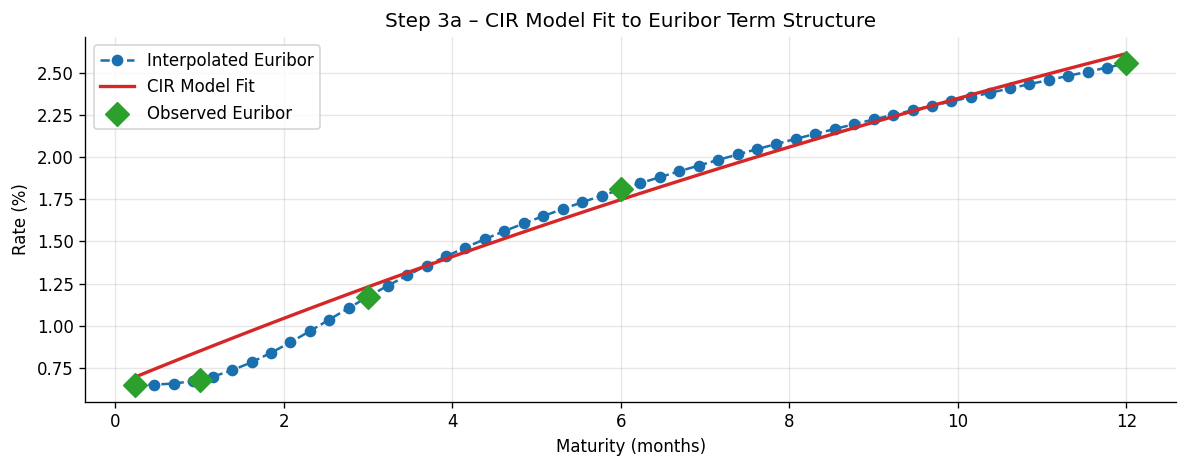

Plot saved: plot_3a_cir_fit.png


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 3a – CIR Model Calibration to Euribor Term Structure")
print("="*60)

"""
CIR SDE: dr_t = κ(θ - r_t)dt + σ√r_t dW_t
Feller: 2κθ > σ² (ensures r_t > 0)

Bond price: P(0,T) = A(T) * exp(-B(T) * r0)
A(T) = [2γ exp((κ+γ)T/2) / (2γ + (κ+γ)(exp(γT)-1))]^(2κθ/σ²)
B(T) = 2(exp(γT)-1) / (2γ + (κ+γ)(exp(γT)-1))
γ    = sqrt(κ² + 2σ²)
"""

# Euribor data
euribor_tenors = np.array([1/52, 1/12, 3/12, 6/12, 12/12])  # years
euribor_rates  = np.array([0.00648, 0.00679, 0.01173, 0.01809, 0.02556])

# Cubic spline interpolation to weekly rates for 1 year
weeks = np.arange(1, 53)
weekly_T = weeks / 52.0
cs = CubicSpline(euribor_tenors, euribor_rates, bc_type="natural")
weekly_rates = np.maximum(cs(weekly_T), 0.0001)  # floor at near-zero

print("\nInterpolated weekly Euribor term structure (selected):")
for w, t, rt in zip(weeks[::8], weekly_T[::8], weekly_rates[::8]):
    print(f"  Week {w:2d} (T={t:.3f}y): {rt*100:.4f}%")

# CIR zero-coupon bond price
def cir_bond_price(T, r0, kappa, theta, sigma):
    gamma = np.sqrt(kappa**2 + 2 * sigma**2)
    exp_g = np.exp(gamma * T)
    denom = 2 * gamma + (kappa + gamma) * (exp_g - 1)
    A = (2 * gamma * np.exp((kappa + gamma) * T / 2) / denom) ** (2 * kappa * theta / sigma**2)
    B = 2 * (exp_g - 1) / denom
    return A * np.exp(-B * r0)

def cir_spot_rate(T, r0, kappa, theta, sigma):
    """Convert CIR bond price to continuously-compounded spot rate."""
    P = cir_bond_price(T, r0, kappa, theta, sigma)
    return -np.log(P) / T

def mse_cir(params, tenors, market_rates, r0):
    kappa, theta, sigma = params
    if kappa <= 0 or theta <= 0 or sigma <= 0:
        return 1e8
    if 2 * kappa * theta <= sigma**2:
        return 1e8
    errs = []
    for T, rm in zip(tenors, market_rates):
        try:
            rc = cir_spot_rate(T, r0, kappa, theta, sigma)
            errs.append((rc - rm)**2)
        except Exception:
            errs.append(1e6)
    return np.mean(errs)

r0_cir = euribor_rates[0]   # use 1-week Euribor as r0
bounds_cir = [(0.01, 5), (0.001, 0.2), (0.001, 1.0)]

result_cir = differential_evolution(
    mse_cir, bounds_cir, args=(weekly_T, weekly_rates, r0_cir),
    seed=42, maxiter=3000, tol=1e-10, popsize=20, polish=True
)

kappa_cir, theta_cir, sigma_cir = result_cir.x
feller_cir = 2 * kappa_cir * theta_cir - sigma_cir**2

print("\n── CIR Calibrated Parameters ──")
print(f"  κ (kappa)  = {kappa_cir:.6f}  [mean-reversion speed]")
print(f"  θ (theta)  = {theta_cir:.6f}  [{theta_cir*100:.4f}% long-run rate]")
print(f"  σ (sigma)  = {sigma_cir:.6f}  [rate volatility]")
print(f"  r0         = {r0_cir:.6f}  [{r0_cir*100:.4f}% initial rate]")
print(f"  Feller: 2κθ - σ² = {feller_cir:.6f}  ({'SATISFIED ✓' if feller_cir > 0 else 'VIOLATED ✗'})")
print(f"  MSE = {result_cir.fun:.8f}")

model_rates = np.array([cir_spot_rate(T, r0_cir, kappa_cir, theta_cir, sigma_cir) for T in weekly_T])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly_T * 12, weekly_rates * 100, "o--", label="Interpolated Euribor", color="#1a6faf", linewidth=1.5)
ax.plot(weekly_T * 12, model_rates * 100, "-", label="CIR Model Fit", color="#d62728", linewidth=2)
ax.scatter(euribor_tenors * 12, euribor_rates * 100, s=100, zorder=5, color="#2ca02c", label="Observed Euribor", marker="D")
ax.set_title("Step 3a – CIR Model Fit to Euribor Term Structure")
ax.set_xlabel("Maturity (months)")
ax.set_ylabel("Rate (%)")
ax.legend()
plt.tight_layout()
plt.savefig("./plot_3a_cir_fit.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_3a_cir_fit.png")


In [ ]:
# === CIR Model: Monte Carlo Rate Simulation ===


## CIR Monte Carlo Simulation | 100,000 paths, 250 daily steps



STEP 3b – CIR Monte Carlo: 12-month Euribor Projection

── CIR Monte Carlo Results (T = 1 year, 100,000 simulations) ──
  Expected 12m Euribor in 1 year: 4.2176%
  95% Confidence Interval: [0.1086%, 15.4088%]
  Current 12m Euribor:            2.5560%
  Expected change:                +1.6616%


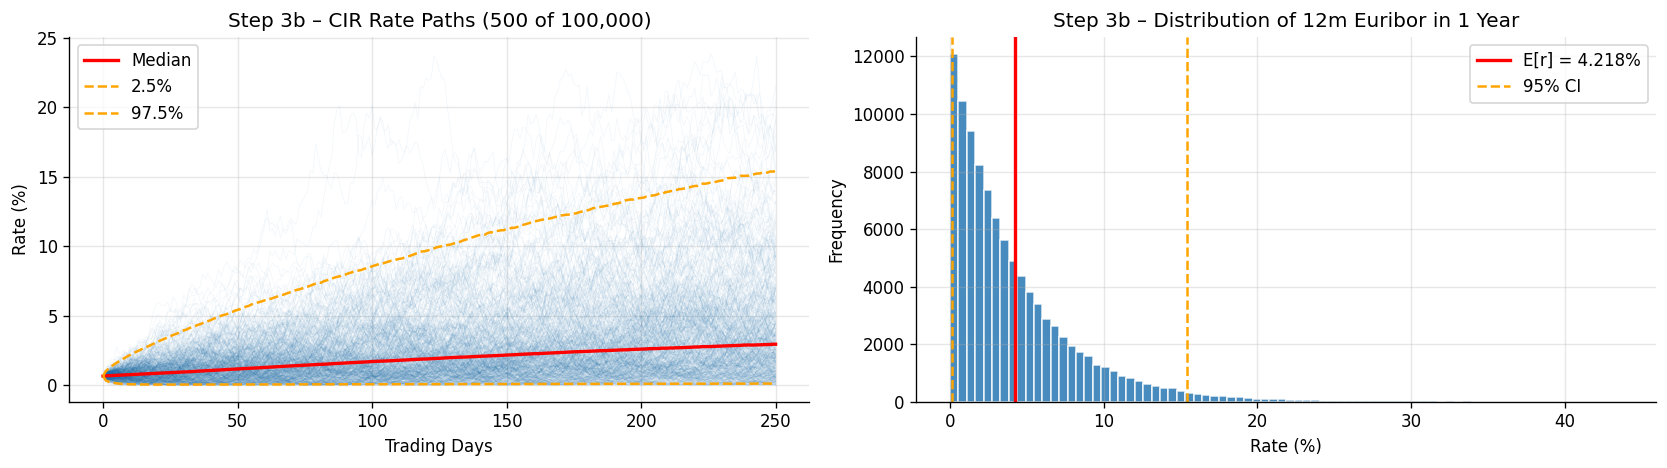

Plot saved: plot_3b_cir_mc.png

── Impact on Asian Option Pricing ──
  Current r = 1.500% → Asian fair price = $12.0326
  Expected r in 1yr = 4.218% → Asian fair price = $12.0651
  Price difference = $+0.0325 (+0.27%)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("STEP 3b – CIR Monte Carlo: 12-month Euribor Projection")
print("="*60)

N_sims_cir  = 100_000
N_days      = 250
dt_cir      = 1 / DAYS_PER_YEAR
np.random.seed(42)

r_paths = np.zeros((N_sims_cir, N_days + 1))
r_paths[:, 0] = r0_cir

for t in range(1, N_days + 1):
    r_pos = np.maximum(r_paths[:, t - 1], 0)
    Z = np.random.standard_normal(N_sims_cir)
    r_paths[:, t] = np.maximum(
        r_pos
        + kappa_cir * (theta_cir - r_pos) * dt_cir
        + sigma_cir * np.sqrt(r_pos * dt_cir) * Z,
        0
    )

final_rates = r_paths[:, -1]
expected_r  = final_rates.mean()
conf_level  = 0.95
q_low  = np.percentile(final_rates, (1 - conf_level) / 2 * 100)
q_high = np.percentile(final_rates, (1 + conf_level) / 2 * 100)

print(f"\n── CIR Monte Carlo Results (T = 1 year, {N_sims_cir:,} simulations) ──")
print(f"  Expected 12m Euribor in 1 year: {expected_r*100:.4f}%")
print(f"  {conf_level*100:.0f}% Confidence Interval: [{q_low*100:.4f}%, {q_high*100:.4f}%]")
print(f"  Current 12m Euribor:            {euribor_rates[-1]*100:.4f}%")
print(f"  Expected change:                {(expected_r - euribor_rates[-1])*100:+.4f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t_days = np.arange(N_days + 1)
for i in range(500):
    axes[0].plot(t_days, r_paths[i] * 100, alpha=0.05, color="#1a6faf", linewidth=0.5)
axes[0].plot(t_days, np.percentile(r_paths, 50, axis=0) * 100, color="red", linewidth=2, label="Median")
axes[0].plot(t_days, np.percentile(r_paths, 2.5, axis=0) * 100, color="orange", linewidth=1.5, linestyle="--", label="2.5%")
axes[0].plot(t_days, np.percentile(r_paths, 97.5, axis=0) * 100, color="orange", linewidth=1.5, linestyle="--", label="97.5%")
axes[0].set_title(f"Step 3b – CIR Rate Paths (500 of {N_sims_cir:,})")
axes[0].set_xlabel("Trading Days"); axes[0].set_ylabel("Rate (%)")
axes[0].legend()

axes[1].hist(final_rates * 100, bins=80, color="#1a6faf", edgecolor="white", alpha=0.8)
axes[1].axvline(expected_r * 100, color="red", linewidth=2, label=f"E[r] = {expected_r*100:.3f}%")
axes[1].axvline(q_low * 100, color="orange", linewidth=1.5, linestyle="--", label=f"95% CI")
axes[1].axvline(q_high * 100, color="orange", linewidth=1.5, linestyle="--")
axes[1].set_title("Step 3b – Distribution of 12m Euribor in 1 Year")
axes[1].set_xlabel("Rate (%)"); axes[1].set_ylabel("Frequency")
axes[1].legend()
plt.tight_layout()
plt.savefig("./plot_3b_cir_mc.png", bbox_inches="tight")
plt.show()
print("Plot saved: plot_3b_cir_mc.png")

# Pricing implication at expected future rate
asian_future_fair, _, _ = heston_mc_asian(
    S0, S0, T_asian, expected_r,
    kappa_mc, theta_mc, sigma_mc, rho_mc, v0_mc,
    N_sims, N_steps
)
print(f"\n── Impact on Asian Option Pricing ──")
print(f"  Current r = {r*100:.3f}% → Asian fair price = ${asian_fair:.4f}")
print(f"  Expected r in 1yr = {expected_r*100:.3f}% → Asian fair price = ${asian_future_fair:.4f}")
print(f"  Price difference = ${asian_future_fair - asian_fair:+.4f} ({(asian_future_fair/asian_fair - 1)*100:+.2f}%)")


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY TABLE
# ─────────────────────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("FINAL SUMMARY")
print("="*60)
print(f"\nStep 1a – Heston Lewis (T=15d): κ={kappa_a:.4f}, θ={theta_a:.4f}, σ={sigma_a:.4f}, ρ={rho_a:.4f}, v0={v0_a:.4f}")
print(f"Step 1b – Heston CM   (T=15d): κ={kappa_b:.4f}, θ={theta_b:.4f}, σ={sigma_b:.4f}, ρ={rho_b:.4f}, v0={v0_b:.4f}")
print(f"Step 1c – Asian Call (ATM, T=20d):  Fair = ${asian_fair:.4f} | Client price = ${asian_client:.4f}")
print(f"Step 2a – Bates Lewis (T=60d):  λ={lam_2a:.4f}, μ_J={mu_j_2a:.4f}, δ_J={delta_j_2a:.4f}")
print(f"Step 2b – Bates CM    (T=60d):  λ={lam_2b:.4f}, μ_J={mu_j_2b:.4f}, δ_J={delta_j_2b:.4f}")
print(f"Step 2c – Put (95%, T=70d):     Fair = ${put_price:.4f} | Client price = ${put_price*1.04:.4f}")
print(f"Step 3a – CIR: κ={kappa_cir:.4f}, θ={theta_cir:.6f}, σ={sigma_cir:.4f}")
print(f"Step 3b – E[12m Euribor in 1yr] = {expected_r*100:.4f}% | 95% CI: [{q_low*100:.4f}%, {q_high*100:.4f}%]")
print("\n✓ All steps complete. Plots saved")


FINAL SUMMARY

Step 1a – Heston Lewis (T=15d): κ=5.9080, θ=0.1191, σ=0.1821, ρ=-0.3305, v0=0.7001
Step 1b – Heston CM   (T=15d): κ=10.7592, θ=0.9238, σ=1.7944, ρ=-0.5725, v0=0.2296
Step 1c – Asian Call (ATM, T=20d):  Fair = $12.0326 | Client price = $12.5139
Step 2a – Bates Lewis (T=60d):  λ=4.7866, μ_J=0.0730, δ_J=0.2558
Step 2b – Bates CM    (T=60d):  λ=2.0722, μ_J=0.2381, δ_J=0.3815
Step 2c – Put (95%, T=70d):     Fair = $39.7680 | Client price = $41.3587
Step 3a – CIR: κ=0.6963, θ=0.077514, σ=0.3285
Step 3b – E Euribor in 1yr] = 4.2176% | 95% CI: [0.1086%, 15.4088%]

✓ All steps complete. Plots saved
